
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining S&P 500 Sectors.  Construct portfolios from the S&P 500 Sector ETFs and examine the results of different weighting schemes.  In particular, we can select the best performing sectors over a given period.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['etf-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='1 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,SPY,S&P 500 ETF,US Stocks:Large Cap,19.25,14.96,18.05,15.79,19.12,12.75,12.11,7.25,12.75,12.91,15.76,18.05,12.91,1.40
1,DIA,DJIA ETF,US Stocks:Large Cap,31.57,14.90,18.57,16.69,15.63,10.32,12.78,8.66,9.60,12.11,14.87,18.57,12.11,1.53
2,QQQ,Nasdaq 100 ETF,US Stocks:Growth,14.47,17.08,21.08,17.03,22.45,14.12,23.64,12.79,21.34,17.65,20.96,21.08,17.65,1.19
3,VTI,Vanguard Total Stock Market Index ETF,US Stocks:Total Stock Market,21.03,15.35,18.53,16.27,18.86,11.77,11.82,7.02,12.57,13.31,15.99,18.53,13.31,1.39
4,IWM,Russell 2000 ETF,US Stocks:Small Cap,35.01,24.52,32.75,30.09,15.86,7.34,13.19,7.14,15.05,19.73,20.61,32.75,19.73,1.66
5,MDY,S&P 400 Midcap ETF,US Stocks:Mid Cap,23.63,18.53,18.66,17.46,12.87,8.64,11.94,7.70,11.32,15.61,18.04,18.66,15.61,1.20
6,IWD,Russell 1000 Value ETF,US Stocks:Value,50.49,32.51,28.66,27.95,17.59,11.79,9.85,5.36,10.06,12.52,14.86,28.66,12.52,2.29
7,IWF,Russell 1000 Growth ETF,US Stocks:Growth,-4.20,-1.16,7.36,3.73,19.14,11.54,22.27,12.66,17.64,16.70,19.39,7.36,16.70,0.44
8,RSP,S&P 500 Equal Weight ETF,US Stocks:Growth,35.47,19.95,17.38,17.52,13.52,9.24,9.96,5.40,9.72,12.96,15.78,17.38,12.96,1.34
9,SPSM,S&P 600 Small Cap ETF,US Stocks:Small Cap,37.81,32.43,31.33,29.55,13.81,8.00,11.93,7.12,14.20,19.11,20.03,31.33,19.11,1.64


In [6]:
# Sector Ranking
sector_rank = bb.rank(df, rank_by='Sharpe Ratio')
sector_rank = sector_rank[sector_rank['Description'].str.contains('Sector ETF')]
#sector_rank = sector_rank.loc[(sector_rank['3 mo'] > 0) & sector_rank['1 Yr'] > 0]
#sector_rank = rank_filtered.head(10)
sector_rank

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
16,XLE,S&P500 Energy Sector ETF,US Stocks:Energy,2.43,42.63,36.70,37.31,14.66,23.77,20.29,9.54,22.27,19.52,25.75,36.70,19.52,1.88
23,XLV,S&P500 Healthcare Sector ETF,US Stocks:Healthcare,74.79,14.22,23.76,25.02,8.16,6.41,20.81,9.74,14.68,13.93,14.80,23.76,13.93,1.71
19,XLK,S&P500 Technology Sector ETF,US Stocks:Technology,49.51,39.35,33.78,26.81,26.18,18.99,33.44,16.09,30.14,22.92,23.93,33.78,22.92,1.47
18,XLI,S&P500 Industrials Sector ETF,US Stocks:Industrials,22.65,19.37,18.29,15.81,19.32,13.27,16.30,12.42,16.51,16.17,18.41,18.29,16.17,1.13
14,XLB,S&P500 Materials Sector ETF,US Stocks:Materials,7.03,8.64,15.97,15.75,8.56,7.04,18.53,10.29,15.40,15.68,19.24,15.97,15.68,1.02
20,XLP,S&P500 Consumer Staples Sector ETF,US Stocks:Consumer Staples,16.05,10.53,8.19,11.31,6.90,6.69,21.00,10.33,15.17,12.11,13.44,8.19,12.11,0.68
17,XLF,S&P500 Financials Sector ETF,US Stocks:Financials,47.31,17.72,9.63,8.46,19.11,11.42,14.04,8.60,11.98,14.35,17.69,9.63,14.35,0.67
21,XLRE,S&P500 Real Estate Sector ETF,US Stocks:Real Estate,20.23,26.83,9.62,13.07,9.07,3.15,15.51,7.52,13.16,16.59,19.18,9.62,16.59,0.58
22,XLU,S&P500 Utilities Sector ETF,US Stocks:Utilities,-6.28,9.10,8.55,10.41,12.64,9.86,15.79,7.31,14.42,15.02,16.44,8.55,15.02,0.57
15,XLC,S&P500 Communication Services Sector ETF,US Stocks:Communication Services,-26.20,-15.69,1.70,3.59,18.72,6.61,21.70,15.46,13.81,13.77,18.60,1.70,13.77,0.12


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# S&P 500 Sectors - top 4
top_sectors_portfolio = {
    'Title': 'Top S&P500 Sectors Portfolio'
}
top_sectors = list(sector_rank['Investment Option'])[:4]
top_sectors_portfolio.update(dict.fromkeys(top_sectors, 1/len(top_sectors)))

# S&P 500 Sectors - all
all_sectors_portfolio = {
    'Title': 'All S&P500 Sectors Portfolio'
}
all_sectors = list(sector_rank['Investment Option'])
all_sectors_portfolio.update(dict.fromkeys(all_sectors, 1/len(all_sectors)))

### Custom Portfolios

In [8]:
# my portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = all_sectors_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,XLE,XLV,XLK,XLI,XLB,XLP,XLF,XLRE,XLU,XLC,XLY,All S&P500 Sectors Portfolio
Annual Returns,36.70,23.76,33.78,18.29,15.97,8.19,9.63,9.62,8.55,1.70,0.85,15.52
Std Dev,19.52,13.93,22.92,16.17,15.68,12.11,14.35,16.59,15.02,13.77,17.77,9.09
Sharpe Ratio,1.88,1.71,1.47,1.13,1.02,0.68,0.67,0.58,0.57,0.12,0.05,1.71
Weight,0.10,0.10,0.06,0.08,0.10,0.10,0.10,0.10,0.10,0.07,0.06,1.00
Worst Typical Down Year,-2.34,-4.10,-12.06,-14.05,-15.39,-16.03,-19.07,-23.56,-21.49,-25.84,-34.69,-2.66
Black Swan,-21.86,-18.03,-34.98,-30.22,-31.07,-28.14,-33.42,-40.15,-36.51,-39.61,-52.46,-11.74


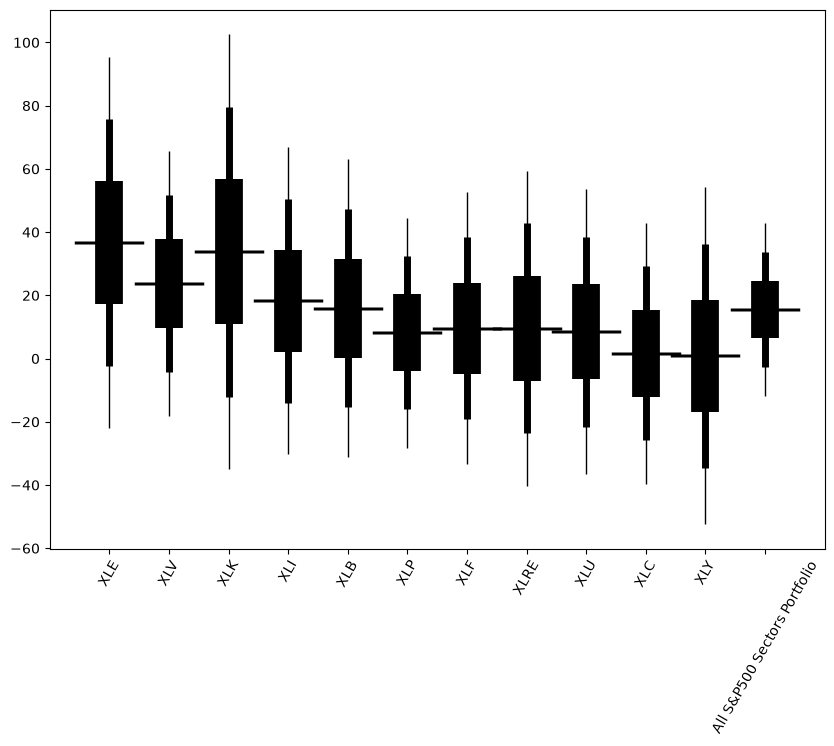

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

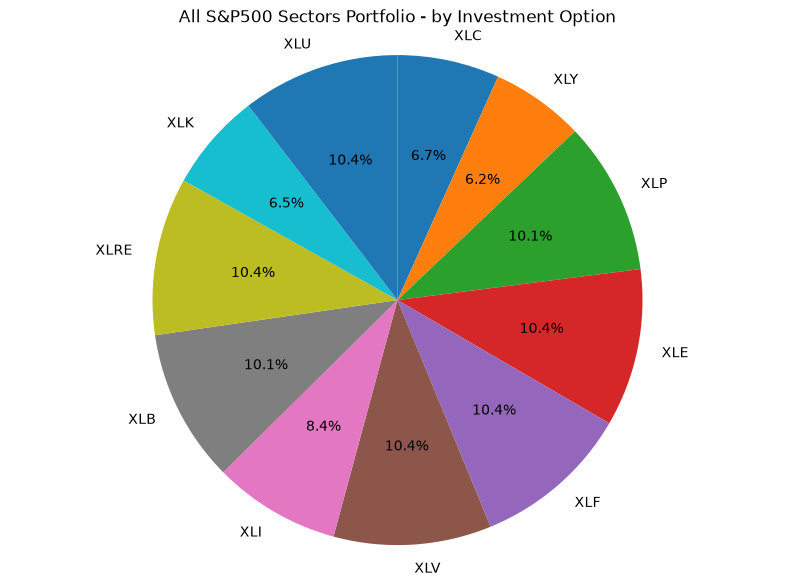

XLC    0.07
XLY    0.06
XLP    0.10
XLE    0.10
XLF    0.10
XLV    0.10
XLI    0.08
XLB    0.10
XLRE   0.10
XLK    0.06
XLU    0.10



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

All S&P500 Sectors Portfolio Weights:
    XLE                            0.1041
    XLV                            0.1041
    XLK                            0.0647
    XLI                            0.0838
    XLB                            0.1012
    XLP                            0.1008
    XLF                            0.1041
    XLRE                           0.1041
    XLU                            0.1041
    XLC                            0.0673
    XLY                            0.0616


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).